In [1]:
import numpy as np
import glob
import pickle
from scipy.stats import linregress
import matplotlib.pyplot as plt

In [2]:
flist = glob.glob('Flux_Comparison_Surface_Reflectance_Data/flux_comparison_results_raz_ceres_*.pkl')
CERES_sza = []
EMIT_sza=[]
CERES_reflectance=[]
EMIT_reflectance_prime=[]
EMIT_Fup_fullspectrum=[]
EMIT_suf_reflectance=[]

CERES_Fup=[]
CERES_Fdn=[]
EMIT_Fdn=[]
CERES_lons=[]
CERES_lats=[]


for f in flist:
    with open(f,'rb') as f:
        flux_comparison_results=pickle.load(f)
        #print(len(flux_comparison_results['CERES_Lon']))

    if len(flux_comparison_results['CERES_Lon']) ==0: 
        continue
    elif len(flux_comparison_results['CERES_Lon']) >20:
#         print(len(flux_comparison_results['CERES_Lon']))
        continue
    
    
    # print(flux_comparison_results['EMIT_surface_reflectance'])
    # print(flux_comparison_results['CERES_Fup'])
    # sys.exit()
    CERES_sza +=flux_comparison_results['CERES_Sza']
    EMIT_sza +=flux_comparison_results['EMIT_Sza']
    xx=np.array(flux_comparison_results['CERES_Ref'])#*np.array(flux_comparison_results['CERES_Fup_based_on_ADM_filtered'])/np.array(flux_comparison_results['CERES_Fup'])
    CERES_reflectance+=xx.tolist()
    EMIT_reflectance_prime+=(flux_comparison_results['EMIT_Ref'])
    CERES_Fup+=(flux_comparison_results['CERES_Fup'])
    CERES_Fdn+=(flux_comparison_results['CERES_Fdn'])
    EMIT_Fup_fullspectrum+=(flux_comparison_results['EMIT_Fup_fullspectrum'])
    EMIT_Fdn+=(flux_comparison_results['EMIT_Fdn'])
    CERES_lons+=flux_comparison_results['CERES_Lon']
    CERES_lats+=flux_comparison_results['CERES_Lat']
    
    EMIT_suf_reflectance +=flux_comparison_results['EMIT_surface_reflectance_flatten']
    
CERES_reflectance=(np.array(CERES_reflectance))
EMIT_reflectance_prime=(np.array(EMIT_reflectance_prime))
CERES_Fup=(np.array(CERES_Fup))
EMIT_Fup_fullspectrum=(np.array(EMIT_Fup_fullspectrum))
EMIT_Fdn = (np.array(EMIT_Fdn))
EMIT_reflectance_pprime = EMIT_Fup_fullspectrum/EMIT_Fdn
CERES_lons=np.array(CERES_lons)
CERES_lats=np.array(CERES_lats)

In [3]:
# Identify a specific location is over land or ocean
from mpl_toolkits.basemap import Basemap
# Initialize the Basemap instance (global)
m = Basemap()
# Define a function to check if a location is over land
def is_land(lat, lon):
    return m.is_land(lon, lat)  # Basemap expects lon, lat order

# Apply the is_land function to each (lat, lon) pair and create a mask
land_mask = np.array([is_land(lat, lon) for lat, lon in zip(CERES_lats, CERES_lons)])

# Now 'land_mask' is a boolean array where True means the location is on land
print(land_mask.shape,np.sum(land_mask))

ModuleNotFoundError: No module named 'mpl_toolkits.basemap'

In [4]:
import mpl_scatter_density
from mpl_scatter_density import scatter_density_artist

EMIT_ref = EMIT_reflectance_pprime
mask = ~np.isnan(CERES_reflectance) & ~np.isnan(EMIT_reflectance_pprime) & land_mask
print(np.sum(mask))

slope, intcep, rv,pv,_ = linregress(np.array(CERES_Fup)[mask],np.array(EMIT_Fup_fullspectrum)[mask])

fig,ax=plt.subplots(figsize=(6,4))
cs=ax.scatter(np.array(CERES_Fup)[mask],np.array(EMIT_Fup_fullspectrum)[mask],\
              c=np.array(EMIT_sza)[mask] - np.array(CERES_sza)[mask],marker='.',cmap='bwr',vmin=-20,vmax=20)
ax.plot(np.linspace(0.1,550,100),slope*np.linspace(0.1,550,100)+intcep,c='r')
ax.text(10,450,'y={0:6.2f}x +{1:6.2f} \nR={2:4.2f}'.format(slope,intcep,rv),c='r',fontsize=14)
ax.set_xlim(0,550)
ax.set_ylim(0,550)
ax.set_xlabel('CERES_Fup [W $m^{-2}$]',fontsize=12)
ax.set_ylabel('EMIT_Fup (315nm-2.5$\mu$m) [W $m^{-2}$]',fontsize=12)
ax.set_title('Collocated CERES and EMIT Pixels')
ax.plot(np.linspace(0,550,50),np.linspace(0,550,50),c='k')

# Add colorbar with limits
cbar = plt.colorbar(cs, ax=ax, label='SZA (EMIT $-$ CERE)', cmap='bwr')
cbar.set_clim(-20, 20)  # Ensure colorbar limits are set

plt.savefig('../figures/EMIT_CERES_Fup_DirectComparison.png',dpi=300,bbox_inches='tight', pad_inches=0.1)

NameError: name 'land_mask' is not defined

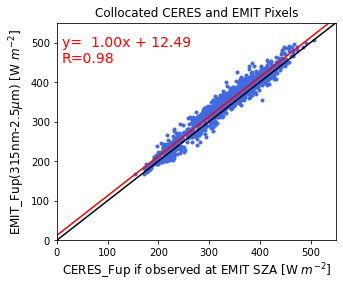

In [6]:
slope, intcep, rv,pv,_ = linregress(np.array(EMIT_Fdn*CERES_reflectance)[mask],np.array(EMIT_Fdn*EMIT_ref)[mask])

fig,ax=plt.subplots(figsize=(5,4))
cs=ax.scatter(np.array(EMIT_Fdn*CERES_reflectance)[mask],np.array(EMIT_Fdn*EMIT_ref)[mask],marker='.',c='royalblue')
ax.plot(np.linspace(0.1,550,100),slope*np.linspace(0.1,550,100)+intcep,c='r')
ax.text(10,450,'y={0:6.2f}x +{1:6.2f} \nR={2:4.2f}'.format(slope,intcep,rv),c='r',fontsize=14)
ax.set_xlabel('CERES_Fup if observed at EMIT SZA [W $m^{-2}$]',fontsize=12)
ax.set_ylabel('EMIT_Fup(315nm-2.5$\mu$m) [W $m^{-2}$]',fontsize=12)
ax.set_title('Collocated CERES and EMIT Pixels')
ax.plot(np.linspace(0,550,50),np.linspace(0,550,50),c='k')

# plt.colorbar(cs, label='EMIT SZA')

ax.set_xlim(0,550)
ax.set_ylim(0,550)

plt.savefig('../figures/EMIT_CERES_Fup_InDirectComparison.png',dpi=300,bbox_inches='tight', pad_inches=0.1)

In [19]:
Fup_diff = np.array(EMIT_Fdn*EMIT_ref)[mask] - np.array(EMIT_Fdn*CERES_reflectance)[mask]
Fup_diff_mean = np.nanmean(Fup_diff)
Fup_diff_std = np.std(Fup_diff)
print(pv)
print(Fup_diff_mean)
print(Fup_diff_std)

0.0
12.954575148441972
14.627227186615482
